In [10]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt

X = pd.read_csv("../data/secom.data", sep=r"\s+", header=None)
labels = pd.read_csv("../data/secom_labels.data", sep=r"\s+", header=None,
                     names=["label", "timestamp"])
labels["timestamp"] = pd.to_datetime(labels["timestamp"], dayfirst=True)
y = (labels["label"] == 1).astype(int)

order = labels["timestamp"].argsort(kind="stable")
X = X.iloc[order].reset_index(drop=True)
y = y.iloc[order].reset_index(drop=True)
ts = labels["timestamp"].iloc[order].reset_index(drop=True)
X.columns = [f"s{i}" for i in X.columns]

split = int(len(X) * 0.7)
is_train = np.arange(len(X)) < split
top = pd.read_csv("../data/processed/top_sensors.csv", index_col=0).index[:5].tolist()
print("Monitoring:", top)

Monitoring: ['s59', 's460', 's205', 's587', 's102']


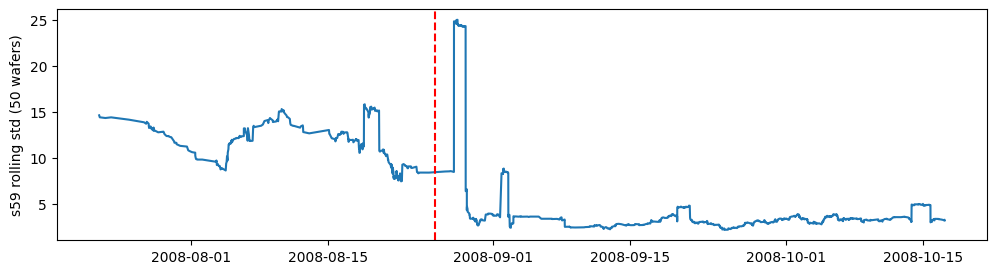

Fail rate before change: 10.5% | after: 4.1%
s59 std before: 13.03 | after: 3.95


In [11]:
roll_sd = X["s59"].rolling(50, min_periods=20).std()
plt.figure(figsize=(12, 3)); plt.plot(ts, roll_sd); plt.ylabel("s59 rolling std (50 wafers)")
plt.axvline(pd.Timestamp("2008-08-26"), color="r", ls="--"); plt.show()
change = pd.Timestamp("2008-09-01")
pre = (ts < change).values
print(f"Fail rate before change: {y[pre].mean():.1%} | after: {y[~pre].mean():.1%}")
print(f"s59 std before: {X.loc[pre, 's59'].std():.2f} | after: {X.loc[~pre, 's59'].std():.2f}")

In [18]:
change = pd.Timestamp("2008-09-01")

def imr_limits(x):
    x = x.dropna()
    mr = x.diff().abs().dropna()
    center, mrbar = x.mean(), mr.mean()
    sigma = mrbar / 1.128
    return {"center": center, "sigma": sigma,
            "ucl": center + 3 * sigma, "lcl": center - 3 * sigma,
            "mrbar": mrbar, "mr_ucl": 3.267 * mrbar}

baseline = lambda s: X.loc[is_train & (y == 0).values & (ts >= change).values, s]

print("Baseline wafers:", baseline("s59").notna().sum())
print(imr_limits(baseline("s59")))

Baseline wafers: 462
{'center': np.float64(0.16326060606060613), 'sigma': np.float64(2.838598829248781), 'ucl': np.float64(8.679057093806948), 'lcl': np.float64(-8.352535881685737), 'mrbar': np.float64(3.2019394793926246), 'mr_ucl': np.float64(10.460736279175704)}


In [19]:
def we_rules(z):
    z = pd.Series(z)
    side = lambda cond, n, k: (cond.astype(int).rolling(n).sum() >= k)
    return pd.DataFrame({
        "R1": z.abs() > 3,                                    # 1 point beyond 3σ
        "R2": side(z > 2, 3, 2) | side(z < -2, 3, 2),         # 2 of 3 beyond 2σ, same side
        "R3": side(z > 1, 5, 4) | side(z < -1, 5, 4),         # 4 of 5 beyond 1σ, same side
        "R4": side(z > 0, 8, 8) | side(z < 0, 8, 8),          # 8 in a row on one side
    })

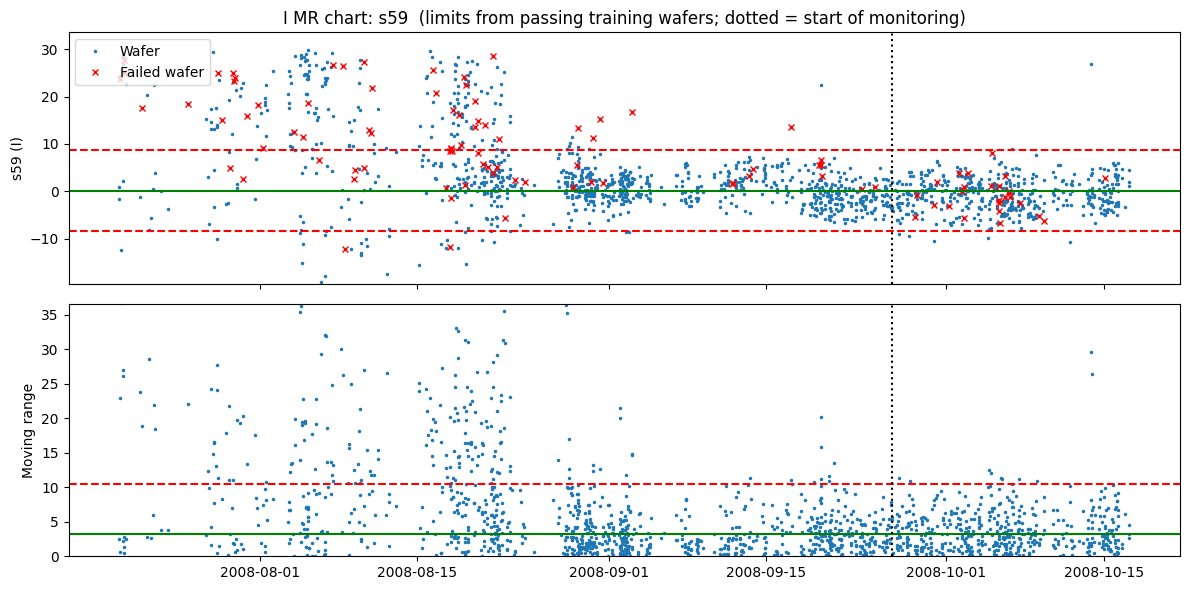

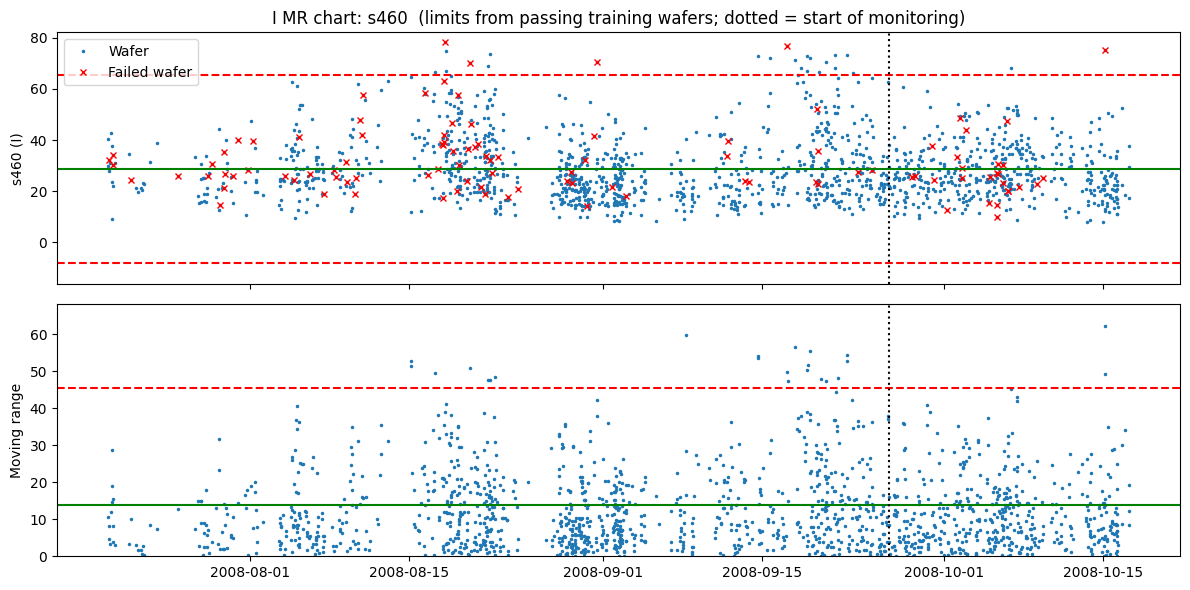

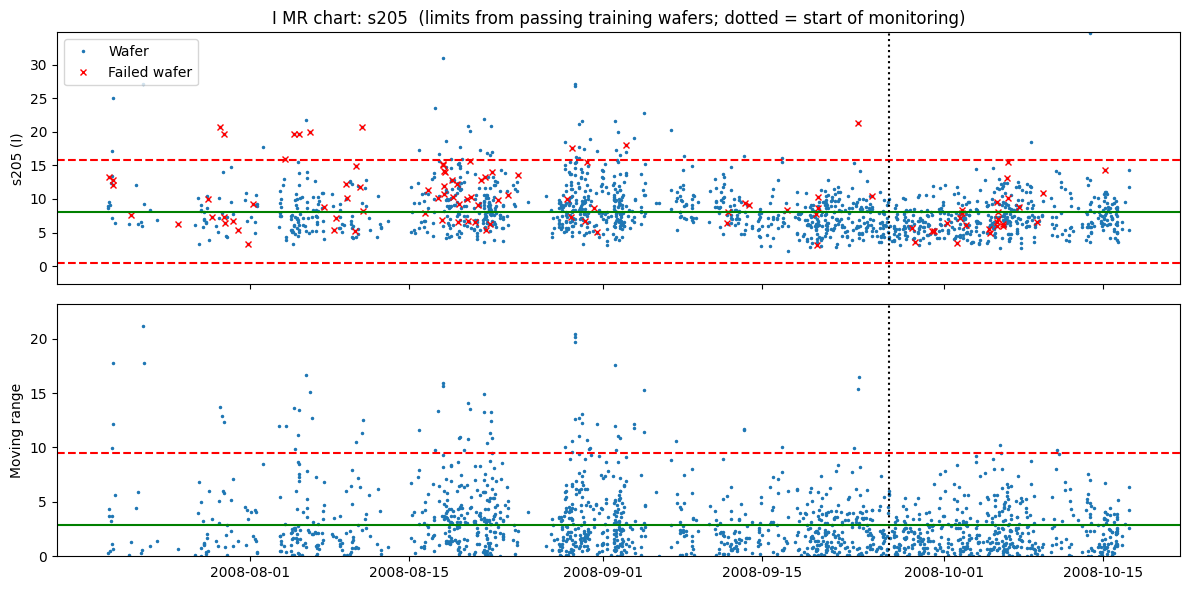

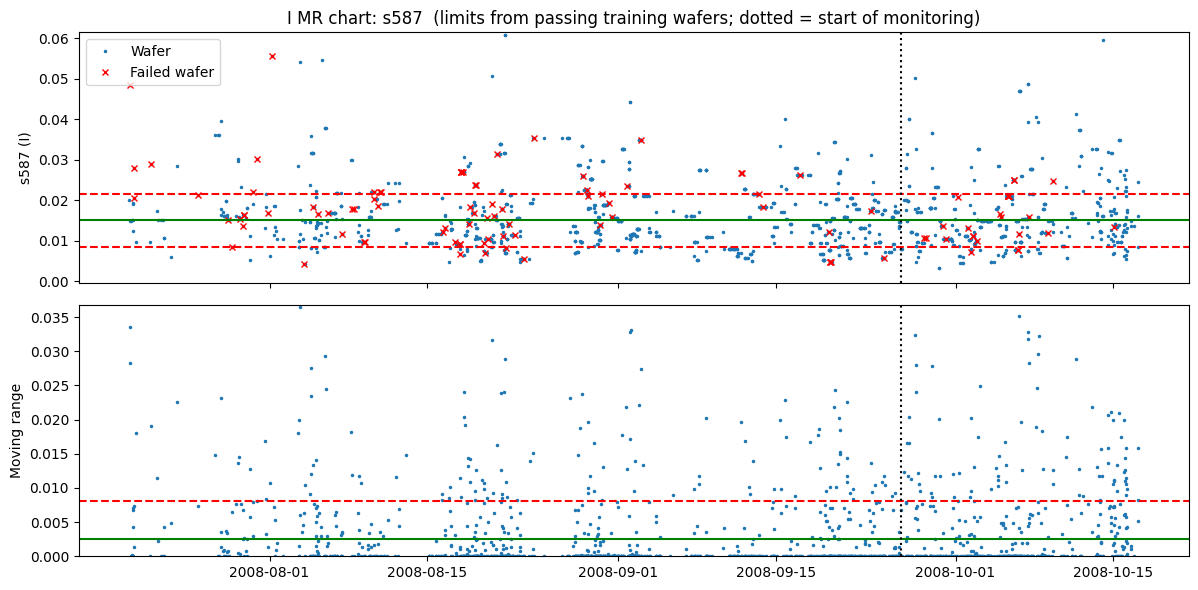

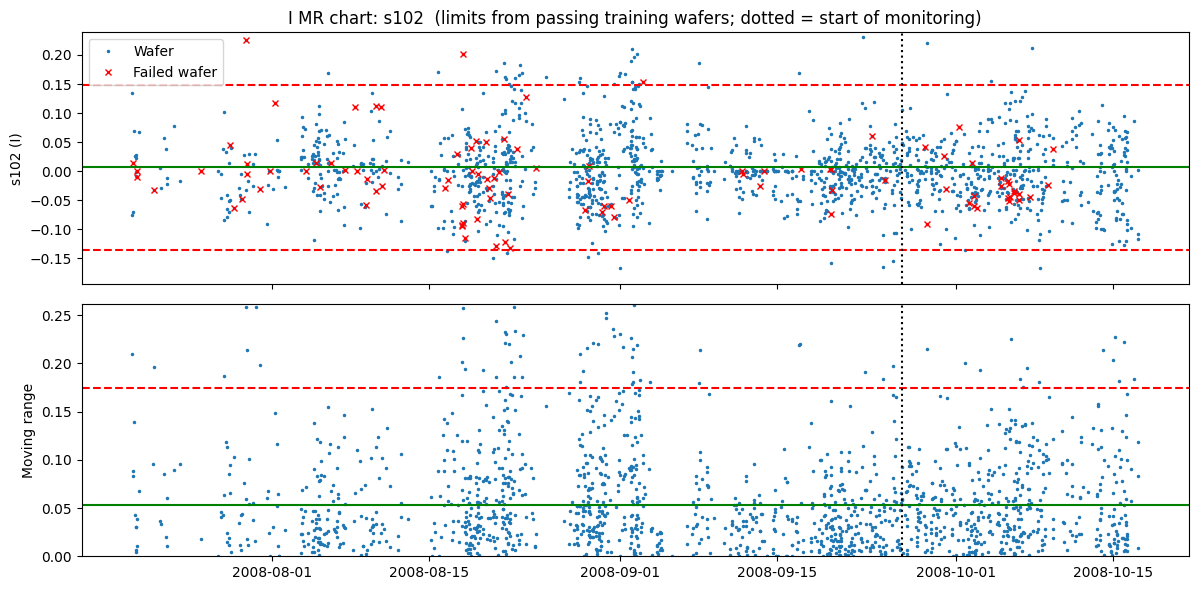

In [20]:
def plot_imr(s):
    lim = imr_limits(baseline(s))
    x, mr, fail = X[s], X[s].diff().abs(), (y == 1).values
    fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

    ax[0].plot(ts, x, ".", ms=3, label="Wafer")
    ax[0].plot(ts[fail], x[fail], "rx", ms=5, label="Failed wafer")
    ax[0].axhline(lim["center"], color="green")
    ax[0].axhline(lim["ucl"], color="red", ls="--")
    ax[0].axhline(lim["lcl"], color="red", ls="--")
    lo = min(lim["lcl"], x.quantile(0.005)); hi = max(lim["ucl"], x.quantile(0.995))
    ax[0].set_ylim(lo - 0.1 * (hi - lo), hi + 0.1 * (hi - lo))   # extreme points off scale
    ax[0].set_ylabel(f"{s} (I)"); ax[0].legend(loc="upper left")

    ax[1].plot(ts, mr, ".", ms=3)
    ax[1].axhline(lim["mrbar"], color="green")
    ax[1].axhline(lim["mr_ucl"], color="red", ls="--")
    ax[1].set_ylim(0, max(lim["mr_ucl"] * 1.5, mr.quantile(0.99)))
    ax[1].set_ylabel("Moving range")

    for a in ax: a.axvline(ts[split], color="k", ls=":")
    ax[0].set_title(f"I MR chart: {s}  (limits from passing training wafers; dotted = start of monitoring)")
    plt.tight_layout(); plt.savefig(f"../figures/imr_{s}.png", dpi=150); plt.show()

for s in top:
    plot_imr(s)

In [21]:
yt = y[~is_train].values
rows, r1_flags = [], {}
for s in top:
    lim = imr_limits(baseline(s))
    rules = we_rules((X[s] - lim["center"]) / lim["sigma"])[~is_train]
    r1, anyr = rules["R1"].values, rules.any(axis=1).values
    r1_flags[s] = r1
    rows.append({"sensor": s,
                 "R1 flags": r1.sum(), "fail rate | R1": yt[r1].mean() if r1.any() else np.nan,
                 "any rule flags": anyr.sum(), "fail rate | any": yt[anyr].mean() if anyr.any() else np.nan})
print(f"Test baseline fail rate: {yt.mean():.1%}")
print(pd.DataFrame(rows).round(3).to_string(index=False))

Test baseline fail rate: 5.5%
sensor  R1 flags  fail rate | R1  any rule flags  fail rate | any
   s59         7           0.000              48            0.083
  s460         2           0.500              18            0.111
  s205         5           0.000              46            0.022
  s587       151           0.040             353            0.057
  s102         6           0.167              45            0.067


In [22]:
combo = np.any(np.column_stack([r1_flags[s] for s in top]), axis=1)
for name, f in [("s59 chart alone", r1_flags["s59"]), ("Any top 5 chart (R1)", combo)]:
    tp = yt[f].sum()
    print(f"{name}: flagged {f.sum()}, fails caught {tp}/{yt.sum()}, false alarms {f.sum() - tp}")
print("XGBoost (from Step 3): flagged 126, fails caught 9/26, false alarms 117")

s59 chart alone: flagged 7, fails caught 0/26, false alarms 7
Any top 5 chart (R1): flagged 164, fails caught 7/26, false alarms 157
XGBoost (from Step 3): flagged 126, fails caught 9/26, false alarms 117


In [23]:
rows = []
for s in top:
    b = baseline(s).dropna()
    mu0, sd0 = b.mean(), b.std()
    lsl, usl = mu0 - 4 * sd0, mu0 + 4 * sd0          # ASSUMED spec limits
    t = X.loc[~is_train, s].dropna()
    mu, sd = t.mean(), t.std()
    cpk = min(usl - mu, mu - lsl) / (3 * sd)
    rows.append({"sensor": s, "baseline Cpk": 1.33, "test Cpk": round(cpk, 2),
                 "test mean shift (σ)": round((mu - mu0) / sd0, 2)})
print(pd.DataFrame(rows).to_string(index=False))

sensor  baseline Cpk  test Cpk  test mean shift (σ)
   s59          1.33      1.17                -0.24
  s460          1.33      1.82                -0.06
  s205          1.33      0.51                -0.06
  s587          1.33      0.90                 0.26
  s102          1.33      1.33                -0.14


In [24]:
lim = imr_limits(baseline("s59"))
r1 = (((X["s59"] - lim["center"]) / lim["sigma"]).abs() > 3).values
pre = (ts < change).values

for name, mask in [("Before Sep 1", pre), ("After Sep 1", ~pre)]:
    f, yy = r1[mask], y.values[mask]
    print(f"{name}: {f.mean():.0%} of wafers out of control | "
          f"fail rate when OOC {yy[f].mean():.1%} vs in control {yy[~f].mean():.1%}")

Before Sep 1: 42% of wafers out of control | fail rate when OOC 16.2% vs in control 6.4%
After Sep 1: 1% of wafers out of control | fail rate when OOC 21.4% vs in control 3.9%
